In [121]:
import numpy as np
import matplotlib.pyplot as plt

# global variables
PIC_EVERY = 128 # number of pictures 
N_RUN = 100 # number of steps until a picture is taken
CELL_PROGRESS_CHECK = 4 # how often do we check if a given cell can divide/die
SIZE = 50
WINDOW_SIZE = 3
K_D = 1e-3  # chance of death
K_B = 1e-2 # chance of birth
K_ATTRACTIVE = 1
K_REPULSIVE = 50
ALPHA = 0.1
DELTA_T = 1e-2

In [122]:
# NOTE
# do not add or remove particles in the movement stage, do it before or after
# not concurrently
# The rates k_d and k_a then change to k_a(t) = cell.time*k_a.
# Same for k_d(t) = cell.time*k_d.
# add 0.5 repulsive potential multiplier to daughter

class System():
    def __init__(self, particle_count, max_particles):
        # preallocate the numpy arrays
        self.max_particles = max_particles
        self.n = 0  # start with 0, we'll add particles via new_cell()
        self.pos = np.empty((max_particles, 2))
        self.R   = np.empty((max_particles, 1))
        self.type = np.empty((max_particles, 1), dtype="U10")
        self.k_d = np.empty((max_particles, 1))
        self.k_b = np.empty((max_particles, 1))
        self.t = np.empty((max_particles, 1))

        # add initial particles using new_cell()
        for _ in range(particle_count):
            pos = np.random.uniform(low=0.05*SIZE, high=0.95*SIZE, size=(2,))
            R = np.random.normal(1.0, 1e-1, size=(1,))
            type_ = "normal"
            k_d = K_D
            k_b = K_B
            self.new_cell(pos, R, type_, k_d, k_b)

    def new_cell(self, pos, R, type_, k_d, k_b):
        if self.n >= self.max_particles:
            raise ValueError("Maximum particle capacity reached!")

        i = self.n
        if pos is None or (not isinstance(pos, np.ndarray) and pos == (0,0)) or np.all(pos == 0):
            self.pos[i] = np.random.uniform(low=0.05*SIZE, high=0.95*SIZE, size=(2,))
        else:
            self.pos[i] = pos
        self.R[i] = R
        self.type[i] = type_
        self.k_d[i] = k_d
        self.k_b[i] = k_b
        self.t[i] = 0
        self.n += 1

    def remove_cell(self, i):
        last = self.n - 1  # index of last active particle
        if i != last:
            # Swap particle i with the last active particle
            self.pos[i] = self.pos[last]
            self.R[i]   = self.R[last]
            self.type[i] = self.type[last]
            self.k_d[i] = self.k_d[last]
            self.k_b[i] = self.k_b[last]
            self.t[i] = self.t[last]
        self.n -= 1

    def cell_culling(self):
        # iterate backwards so swapping removal is safe
        for i in range(self.n - 1, -1, -1):

            # mothers and daughters cannot die
            if "_m" in self.type[i,0] or "_d" in self.type[i,0]:
                continue

            # time dependent death rate
            k_d = self.k_d[i] * self.t[i]

            probability_of_death = k_d

            if np.random.rand() < probability_of_death:
                self.remove_cell(i)

    def print_status(self):
        print(f"positions:\n {self.pos[:self.n]}\n")
        print(f"radii:\n {self.R[:self.n]}\n")
        print(f"types:\n {self.type[:self.n]}\n")

    def find_neighbours(self):
        # returns a list of neighbor indices for each particle
        neighbours = []

        for i in range(self.n):
            # compute all the distances
            delta_pos = self.pos[:self.n] - self.pos[i]

            # periodic boundary condition, maintaining the correct sign
            delta_pos -= SIZE * np.round(delta_pos / SIZE)

            # keep only the particles within a given threshold
            mask = (np.abs(delta_pos[:,0]) <= WINDOW_SIZE) & (np.abs(delta_pos[:,1]) <= WINDOW_SIZE)

            mask[i] = False
            vectors = delta_pos[mask]
            radii = self.R[:self.n][mask]

            neighbours.append(list(zip(vectors, radii)))

        return neighbours
    
    def update_pos(self):
        neighbour_list = self.find_neighbours()
        sum_delta_pos = 0
        for i in range(self.n):
            F = np.zeros((2))
            for vec, radius in neighbour_list[i]:
                distance = np.linalg.norm(vec)
                sum_of_radii = self.R[i] + radius

                vec_normalized = vec / distance
                if distance < sum_of_radii:
                    # repulsive
                    repulsive_multiplier = 1.0
                    if "_m" in self.type[i,0] or "_d" in self.type[i,0]:
                        repulsive_multiplier = 0.5 # if it is a daughter or mother (they should be able to push others away)
                    F -= K_REPULSIVE * (sum_of_radii - distance) * vec_normalized * repulsive_multiplier
                elif distance <= 1.1*sum_of_radii:
                    F += K_ATTRACTIVE * vec_normalized

            # now that we have collected all the forces, we can
            # update the position of our particle
            eta = np.random.normal(0, 1.0, size=(2))  # 2D Gaussian
            delta_pos = F * DELTA_T + np.sqrt(ALPHA * DELTA_T) * eta
            sum_delta_pos += np.linalg.norm(delta_pos)
            self.pos[i] += delta_pos

            # check position, make sure it is within bounds
            self.pos[i] = self.pos[i] % SIZE
            # update the time variable for the particle
            self.t[i] += 1
        mobility = sum_delta_pos / self.n

    def cell_division(self):
        # NOTE update the states (mother, daughter, to normal)
        # update mother/daughter → normal
        neighbour_list = self.find_neighbours()

        for i in range(self.n):
            if "_m" not in self.type[i,0] and "_d" not in self.type[i,0]:
                continue

            min_distance = np.inf
            for vec, radius in neighbour_list[i]:
                distance = np.linalg.norm(vec)
                if distance < min_distance:
                    min_distance = distance
            if min_distance > 0.8 * 2 * self.R[i]:
                self.type[i,0] = self.type[i,0][:-2] 


        will_give_birth = []
        # k_# components are to be multiplied by the time component when calculating probability
        neighbour_count = [len(instances) for instances in neighbour_list]
        for i in range(self.n):
            if "_m" in self.type[i,0] or "_d" in self.type[i,0]:
                # mothers and daughters cannot divide
                will_give_birth.append(False)
                continue
            k_b = self.k_b[i] * self.t[i]
            probability_of_birth = k_b * (1.0 - (neighbour_count[i] / 6))
            if probability_of_birth > np.random.rand():
                will_give_birth.append(True)
            else: will_give_birth.append(False)

        # now we have a mask that will tell us if a given cell will give birth
        for i, birth in enumerate(will_give_birth):
            if birth:
                # find the daughter's values
                pos = (self.pos[i].copy() + (1e-1)*np.random.rand(2)) % SIZE # don't forget to apply th PBC
                R = np.random.normal(1.0, 1e-1, size=(1,))
                type = self.type[i,0] + "_d" # to signify daughter
                k_d = self.k_d[i]
                k_b = self.k_b[i]
                self.new_cell(pos, R, type, k_d, k_b)

                # update the moteher's values
                self.R[i] = np.random.normal(1.0, 1e-1, size=(1,))
                self.type[i,0] += "_m"
                self.t[i] = 0


    def print_neighbours(self, neighbours_list):
        """
        Prints each particle's position and its neighbor displacement vectors.
        neighbours_list: output of self.find_neighbours()
        """
        for i in range(self.n):
            print(f"Particle {i}: position = {self.pos[i]}")
            print(f"  Neighbors (dx, dy, R):")
            for vec, radius in neighbours_list[i]:
                print(f"\t{vec}, {radius}")
            print()  # blank line for readability

    def plot_system(self, color_dict=None):
        fig, ax = plt.subplots(figsize=(6,6))

        import numpy as np
        # We no longer need matplotlib.cm since we are specifying colors manually

        legend_added = set()

        ### compute normalization for log(alpha)
        t_values = self.t[:self.n,0]
        log_t = np.log1p(t_values)  # log(1+t)
        max_log_t = np.max(log_t) if np.max(log_t) > 0 else 1

        for i in range(self.n):
            particle_type = self.type[i,0]
            base_type = particle_type.rsplit("_",1)[0]

            # Use the provided color dict, default to gray if not found
            if color_dict and base_type in color_dict:
                color = color_dict[base_type]
            else:
                color = "gray" 

            ### alpha scaling with log(t)
            alpha = 0.2 + 0.6 * (np.log1p(self.t[i,0]) / max_log_t)

            circle = plt.Circle(
                (self.pos[i,0], self.pos[i,1]),
                radius=self.R[i,0],
                color=color,
                alpha=alpha
            )
            ax.add_patch(circle)

            ### legend uses base type only
            if base_type not in legend_added:
                ax.scatter([], [], color=color, alpha=0.8, label=base_type)
                legend_added.add(base_type)

        ax.set_xlim(0, SIZE)
        ax.set_ylim(0, SIZE)
        ax.set_aspect('equal')
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

        plt.tight_layout()
        plt.show()

def just_add_cancer(no_cancer_cells):
    pass

def run_sim(initial_cells, simulation_length, cancer_multiplier=10, introduce_cancer_at=-1, plot=False, color_dict=None, K_B_override_multi = 0):
    system = System(initial_cells, 1024)
    global K_B
    K_B_record = K_B
    if K_B_override_multi>0: K_B = K_B * K_B_override_multi
    # Dictionary to hold the lists of counts for each type
    cell_counts = {}
    
    for i in range(simulation_length):
        if i == introduce_cancer_at: 
            for _ in range(5):
                system.new_cell((0,0), 1, "cancer", K_D, K_B*cancer_multiplier)
        
        current_step_counts = {}
        for j in range(system.n):
            base_type = system.type[j,0].rsplit("_",1)[0]
            current_step_counts[base_type] = current_step_counts.get(base_type, 0) + 1
            
        for base_type in current_step_counts:
            if base_type not in cell_counts:
                cell_counts[base_type] = [0] * i
                
        for base_type in cell_counts:
            cell_counts[base_type].append(current_step_counts.get(base_type, 0))

        system.update_pos()

        if i % CELL_PROGRESS_CHECK == 0:
            system.cell_culling()
            system.cell_division()
        if i % PIC_EVERY == 0 and PIC_EVERY > 0 and plot == True:
            print(f"snapshot at i = {i}")
            system.plot_system(color_dict=color_dict)

    plt.figure(figsize=(8,5))
    for cell_type, counts in cell_counts.items():
        line_color = color_dict.get(cell_type, "gray") if color_dict else None
        plt.plot(counts, label=cell_type, color=line_color)
        
    plt.xlabel("Simulation Step")
    plt.ylabel("Cell Count")
    plt.title(f"Cell Population Over Time K_B = {K_B}")
    plt.legend()
    plt.show()
    
    K_B = K_B_record # return to the original state_
    # return cell_counts

colors = {
    "normal": "blue",
    "cancer": "red",
}


snapshot at i = 0


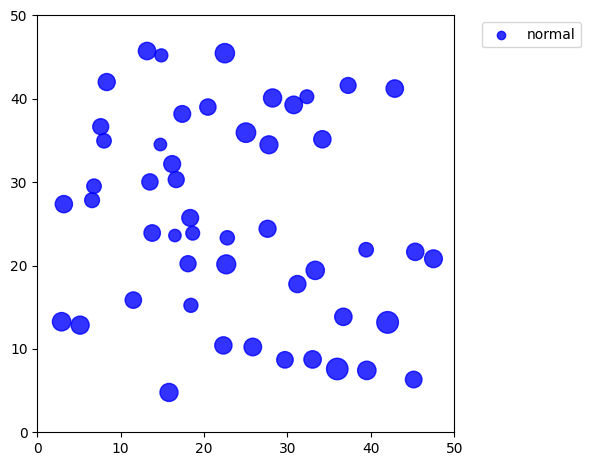

snapshot at i = 128


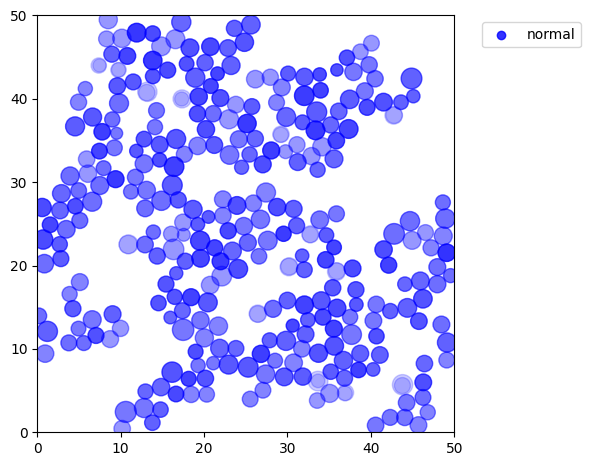

snapshot at i = 256


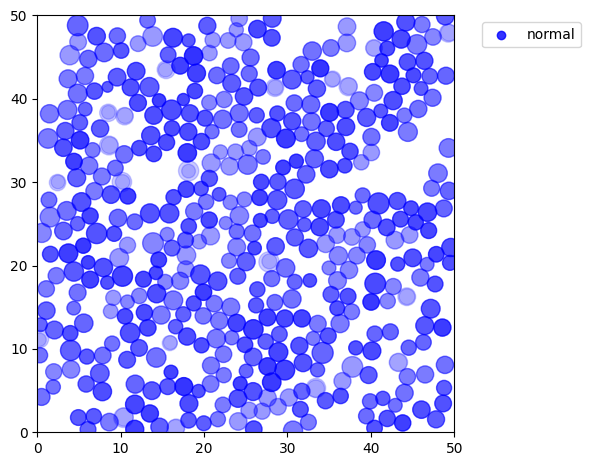

snapshot at i = 384


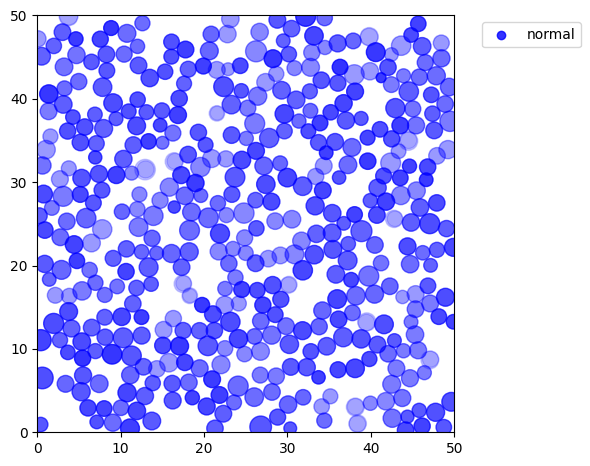

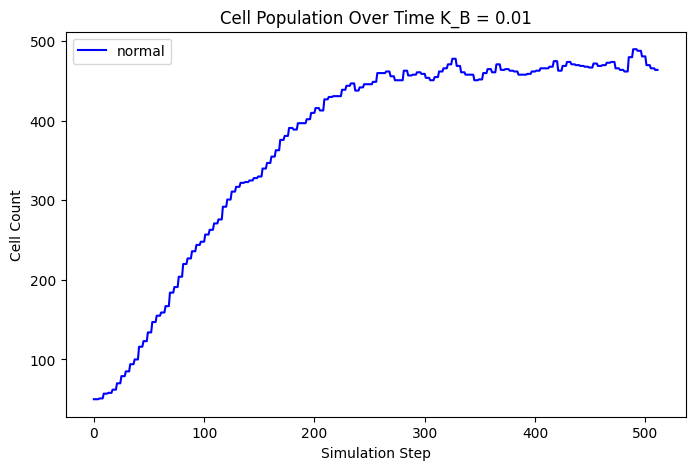

In [123]:
run_sim(50, 512, plot=True, color_dict=colors, introduce_cancer_at=-1)

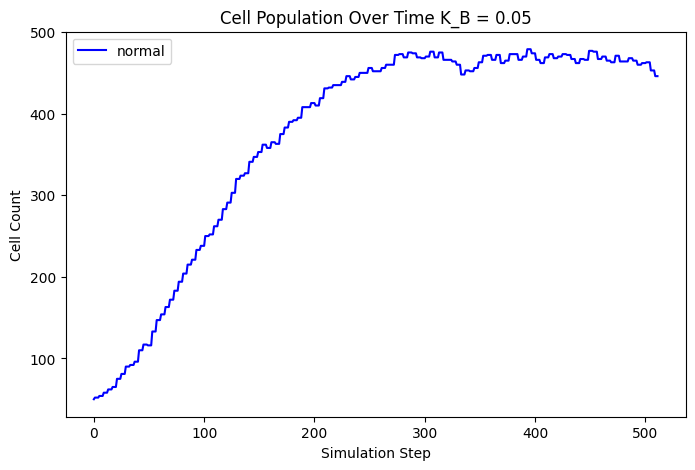

In [124]:
run_sim(50, 512, plot=False, color_dict=colors, K_B_override_multi=5)

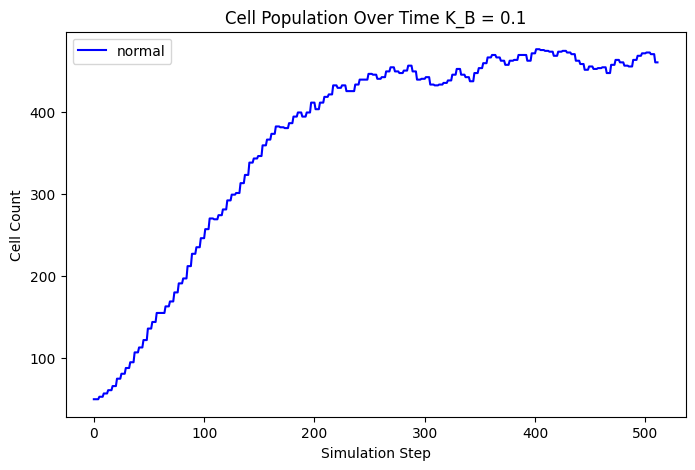

In [125]:
run_sim(50, 512, plot=False, color_dict=colors, K_B_override_multi=10)

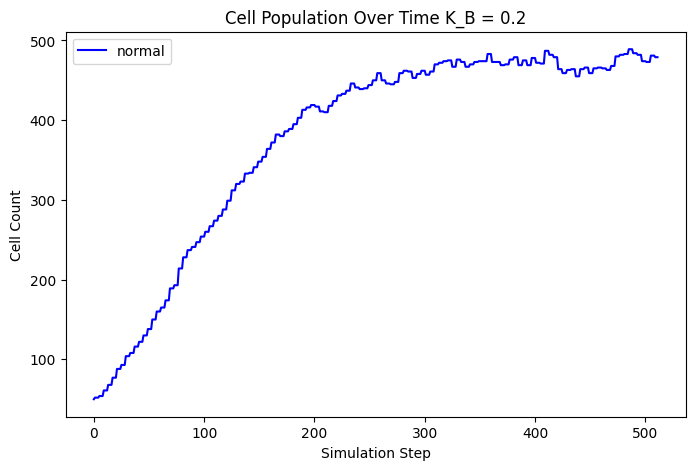

In [126]:
run_sim(50, 512, plot=False, color_dict=colors, K_B_override_multi=20)

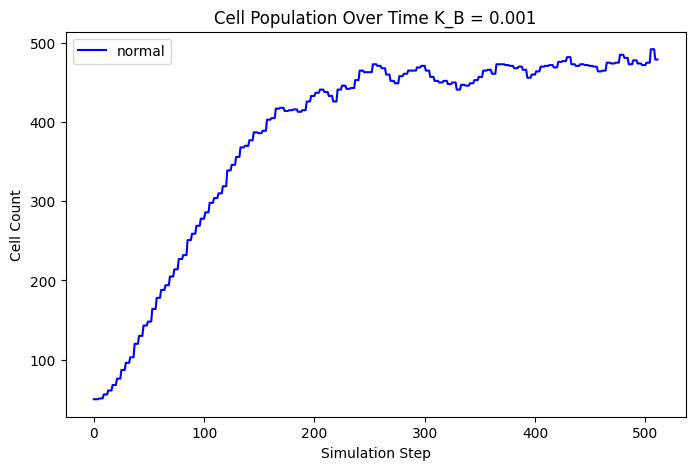

In [127]:
run_sim(50, 512, plot=False, color_dict=colors, K_B_override_multi=0.1)

snapshot at i = 0


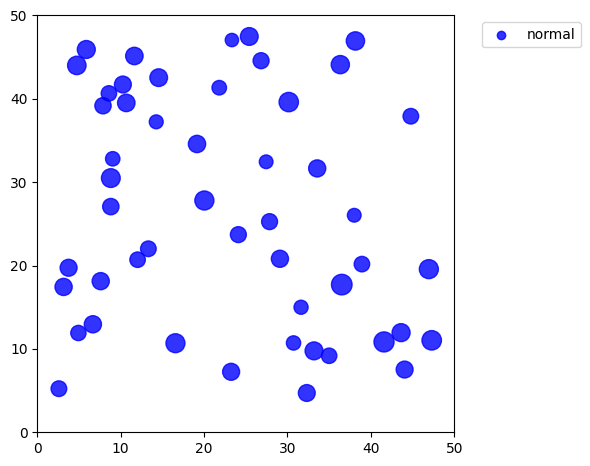

snapshot at i = 128


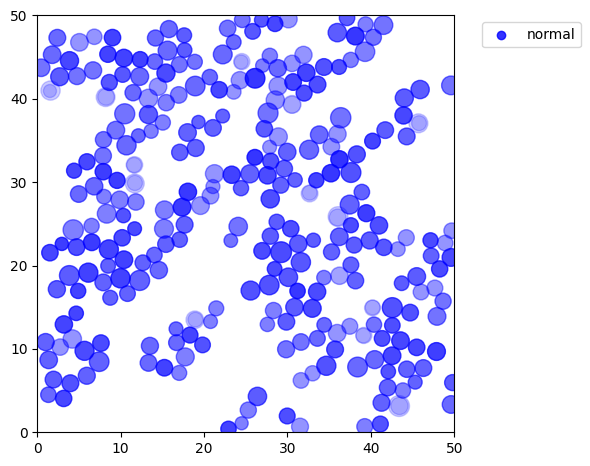

snapshot at i = 256


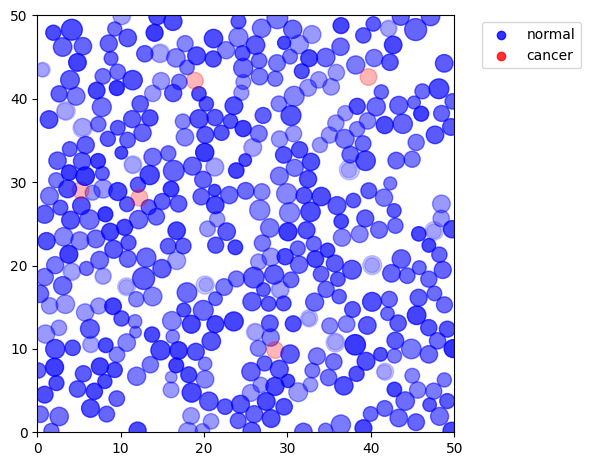

snapshot at i = 384


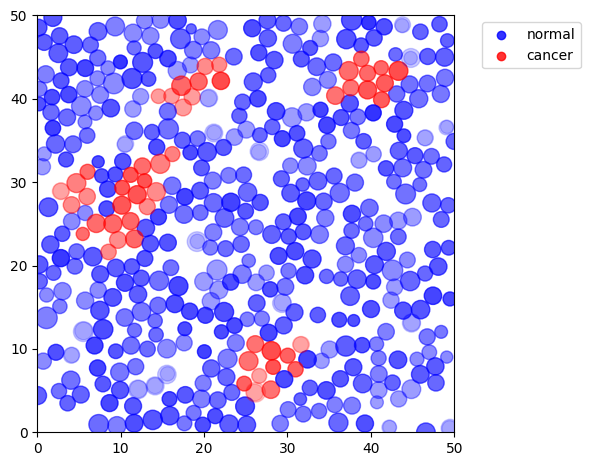

snapshot at i = 512


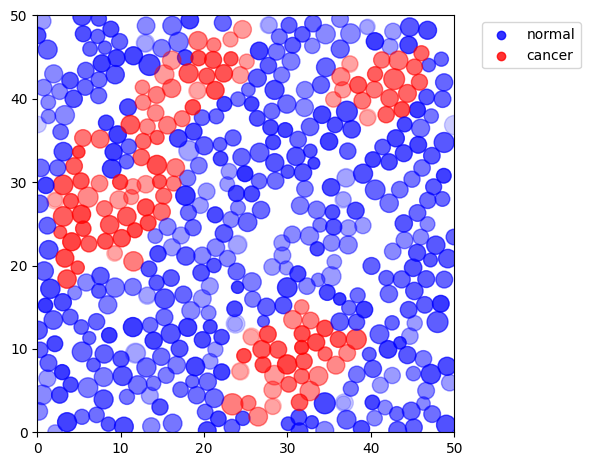

snapshot at i = 640


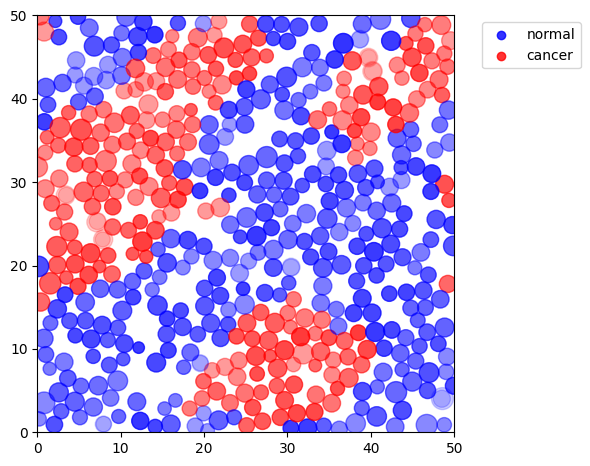

snapshot at i = 768


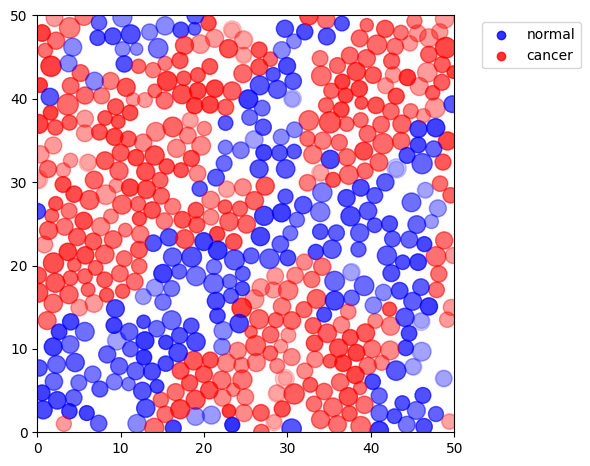

snapshot at i = 896


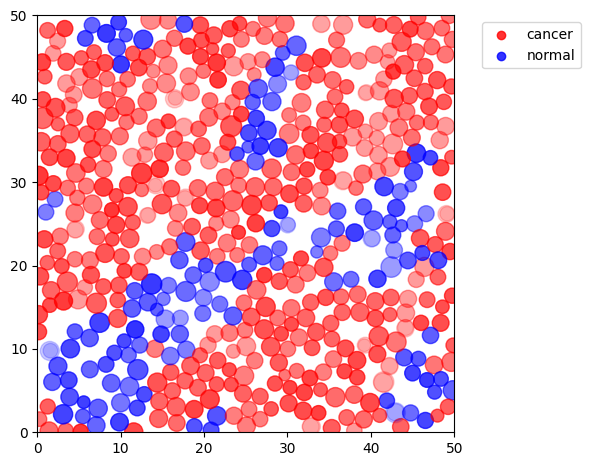

snapshot at i = 1024


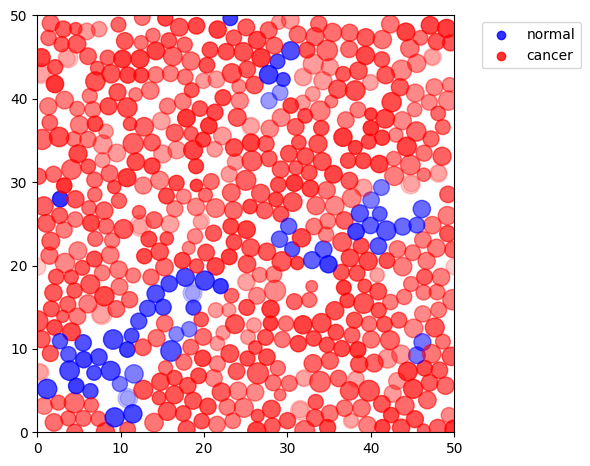

snapshot at i = 1152


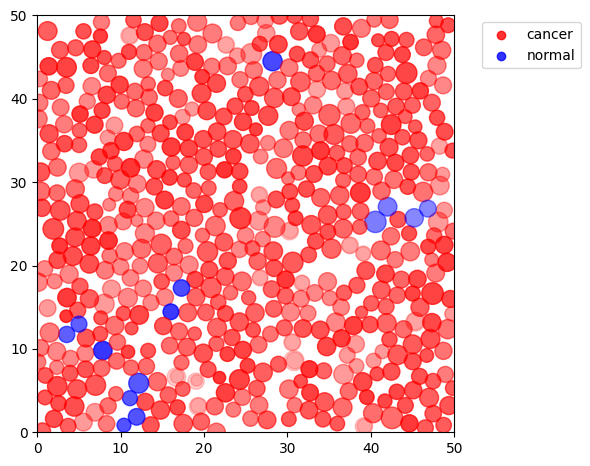

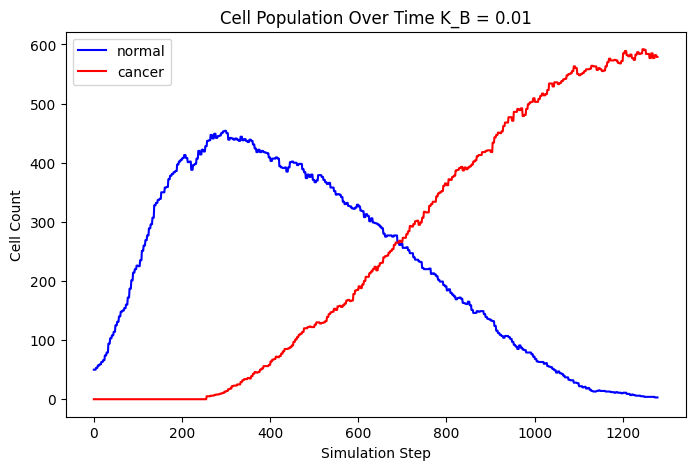

In [128]:
run_sim(50, 256*5, plot=True, color_dict=colors, introduce_cancer_at=256)